In [56]:
import torch
import torchvision
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from torchvision import transforms
from collections import Counter
from torch.utils.data import random_split, DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset
import time
import torchvision.transforms.functional as TF

# Task 1. Study and Prepare the Data

In [57]:
# Download and load CIFAR-10
train_dataset = torchvision.datasets.CIFAR10(root="./data", train=True, download=True,transform=transforms.ToTensor())

test_dataset = torchvision.datasets.CIFAR10(root="./data", train=False, download=True,transform=transforms.ToTensor())

In [58]:
# Analyze the dataset
classes = train_dataset.classes

print("Training samples:", len(train_dataset))
print("Test samples:", len(test_dataset))
print("Image dimensions:", train_dataset.data.shape[1:])
print("Number of classes:", len(classes))
print("Classes:", classes)

Training samples: 50000
Test samples: 10000
Image dimensions: (32, 32, 3)
Number of classes: 10
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [59]:
# Inspect class distribution
class_counts = Counter(train_dataset.targets)

for i, class_name in enumerate(classes):
    print(f"{class_name}: {class_counts[i]}")

airplane: 5000
automobile: 5000
bird: 5000
cat: 5000
deer: 5000
dog: 5000
frog: 5000
horse: 5000
ship: 5000
truck: 5000


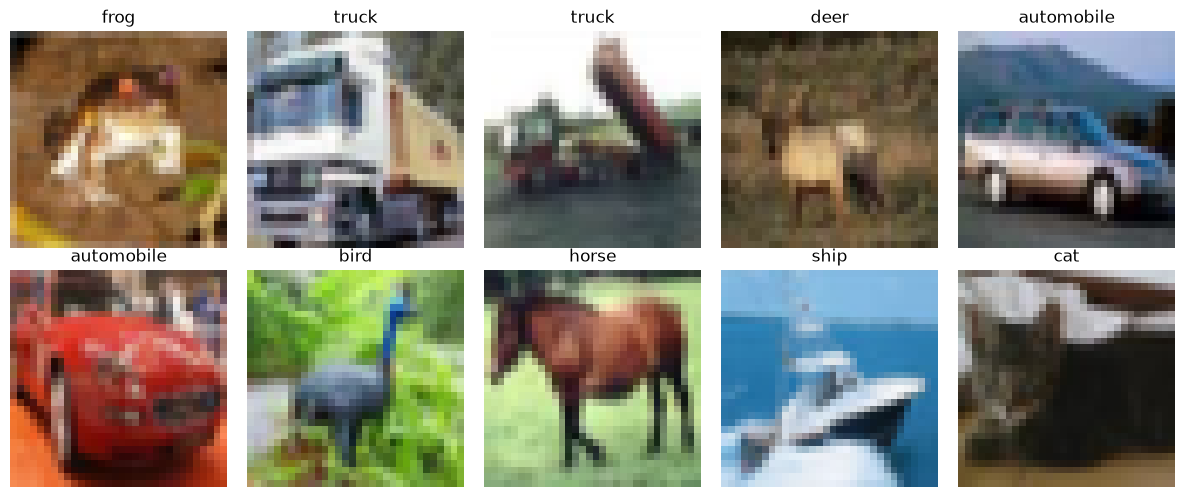

In [60]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image = train_dataset.data[i]
    label = train_dataset.targets[i]

    ax.imshow(image)
    ax.set_title(classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [61]:
# Normalization
# Source: https://stackoverflow.com/questions/66678052/how-to-calculate-the-mean-and-the-std-of-cifar10-data
mean = [0.49139968, 0.48215827 ,0.44653124]
std =  [0.24703233, 0.24348505, 0.26158768]
train_transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)])

eval_transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)])

In [62]:
# Create all 3 splits
seed = 587
rng = np.random.default_rng(seed)
torch.manual_seed(seed)

train_subset, val_subset = random_split(
    train_dataset, [40000, 10000],
    generator=torch.Generator().manual_seed(seed)
)
 # Test already defined in the first cell

print("Training:", len(train_subset))
print("Validation:", len(val_subset))
print("Test:", len(test_dataset))

Training: 40000
Validation: 10000
Test: 10000


In [63]:
# Data loaders for efficient batch processing
train_loader = DataLoader(train_subset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_subset, batch_size=128, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

# Task 2. Implement and Compare the Models


In [64]:
if torch.cuda.is_available(): device = torch.device("cuda")
elif torch.backends.mps.is_available(): device = torch.device("mps")
else: device = torch.device("cpu")

In [65]:
# AlexNet
#width and depth can be changed more easily with this new implementation. extra_convs is depth
class AlexNet(nn.Module):
    
    def __init__(self, num_classes=10, width=1.0, extra_convs=0, dropout=0):
        super().__init__()
        c1, c2, c3, c4, c5 = [int(c * width) for c in (64, 192, 384, 256, 256)]
        h1, h2 = int(1024 * width), int(512 * width)
        layers = [
            nn.Conv2d(3, c1, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2, 2),
            nn.Conv2d(c1, c2, 3, padding=1), nn.ReLU(inplace=True), nn.MaxPool2d(2, 2),
            nn.Conv2d(c2, c3, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(c3, c4, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(c4, c5, 3, padding=1), nn.ReLU(inplace=True),
        ]
        for _ in range(extra_convs):
            layers += [nn.Conv2d(c5, c5, 3, padding=1), nn.ReLU(inplace=True)]
        layers.append(nn.MaxPool2d(2, 2))
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(c5 * 4 * 4, h1), nn.ReLU(inplace=True), nn.Dropout(dropout),
            nn.Linear(h1, h2), nn.ReLU(inplace=True), nn.Dropout(dropout),
            nn.Linear(h2, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

In [66]:
# ResNet
class BasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels, out_channels,
            kernel_size=3, stride=stride, padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(
            out_channels, out_channels,
            kernel_size=3, stride=1, padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels, out_channels,
                    kernel_size=1, stride=stride, bias=False
                ),
                nn.BatchNorm2d(out_channels)
            )

        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        identity = self.shortcut(x)

        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        out += identity
        out = self.relu(out)

        return out

##width and depth can be changed more easily with this new implementation. Blocks is depth
class ResNet18(nn.Module):
    def __init__(self, num_classes=10, width=64, blocks=(2, 2, 2, 2), dropout=0.0):
        super().__init__()
        self.in_channels = width
        self.conv1 = nn.Conv2d(3, width, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(width)
        self.relu = nn.ReLU(inplace=True)

        self.layer1 = self.make_layer(width, blocks[0], stride=1)
        self.layer2 = self.make_layer(width * 2, blocks[1], stride=2)
        self.layer3 = self.make_layer(width * 4, blocks[2], stride=2)
        self.layer4 = self.make_layer(width * 8, blocks[3], stride=2)

        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(width * 8, num_classes)

    def make_layer(self, out_channels, blocks, stride):
        layers = [BasicBlock(self.in_channels, out_channels, stride)]
        self.in_channels = out_channels
        for _ in range(1, blocks):
            layers.append(BasicBlock(self.in_channels, out_channels))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.layer4(self.layer3(self.layer2(self.layer1(x))))
        x = torch.flatten(self.avgpool(x), 1)
        return self.fc(self.drop(x))

In [67]:
# Initiate models
alexnet = AlexNet().to(device)
resnet = ResNet18().to(device)

In [68]:
# Training configuration
criterion = nn.CrossEntropyLoss()

learning_rate = 0.001
epochs = 10

alexnet_optimizer = torch.optim.Adam(alexnet.parameters(), lr=learning_rate)
resnet_optimizer = torch.optim.Adam(resnet.parameters(), lr=learning_rate)

In [69]:
# Logic to train for a single epoch

def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / len(loader), correct / total

    # Evaluate the model
def evaluate(model, loader):
    model.eval()
    correct = 0
    total = 0
    total_loss = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item()
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / len(loader), correct / total

"""
# old one
def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss = 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)
    """




'\n# old one\ndef train_one_epoch(model, loader, optimizer):\n    model.train()\n    total_loss = 0\n    for images, labels in loader:\n        images, labels = images.to(device), labels.to(device)\n        optimizer.zero_grad()\n        outputs = model(images)\n        loss = criterion(outputs, labels)\n        loss.backward()\n        optimizer.step()\n        total_loss += loss.item()\n    return total_loss / len(loader)\n    '

In [70]:
# Training Loop
def train_model(model, optimizer, name, loader=None):
    loader = loader or train_loader #default is train_loader
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_accuracy = 0
    start = time.time()

    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(model, loader, optimizer)
        val_loss, val_accuracy = evaluate(model, val_loader)
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_accuracy)
        print(
            f"{name} | Epoch {epoch+1}/{epochs} | "
            f"Train loss: {train_loss:.4f} | Train acc: {train_acc:.4f} | "
            f"Val loss: {val_loss:.4f} | Val accuracy: {val_accuracy:.4f}"
        )
        if val_accuracy > best_accuracy:
            best_accuracy = val_accuracy
            torch.save(model.state_dict(), f"{name}_best.pth")
            
    history['time'] = time.time() - start
    history['params'] = sum(p.numel() for p in model.parameters())
    print(f"{name} best val acc: {best_accuracy:.4f} | time: {history['time']:.0f}s | params: {history['params']:,}")
    return history

In [71]:
#resets the state for each run
def run(model, name, weight_decay=0.0, loader=None):
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    return train_model(model, opt, name, loader)

In [72]:
# Run Training
results = {}

torch.manual_seed(seed)
results['alex_base'] = run(AlexNet(), "alexnet")

torch.manual_seed(seed)
results['resnet_base'] = run(ResNet18(), "resnet")

alexnet | Epoch 1/10 | Train loss: 1.7450 | Train acc: 0.3441 | Val loss: 1.4438 | Val accuracy: 0.4696
alexnet | Epoch 2/10 | Train loss: 1.2648 | Train acc: 0.5360 | Val loss: 1.1492 | Val accuracy: 0.5862
alexnet | Epoch 3/10 | Train loss: 1.0437 | Train acc: 0.6270 | Val loss: 0.9951 | Val accuracy: 0.6516
alexnet | Epoch 4/10 | Train loss: 0.8656 | Train acc: 0.6923 | Val loss: 0.9295 | Val accuracy: 0.6723
alexnet | Epoch 5/10 | Train loss: 0.7360 | Train acc: 0.7401 | Val loss: 0.8946 | Val accuracy: 0.6902
alexnet | Epoch 6/10 | Train loss: 0.6037 | Train acc: 0.7877 | Val loss: 0.8561 | Val accuracy: 0.7164
alexnet | Epoch 7/10 | Train loss: 0.5001 | Train acc: 0.8249 | Val loss: 0.7998 | Val accuracy: 0.7349
alexnet | Epoch 8/10 | Train loss: 0.3960 | Train acc: 0.8597 | Val loss: 0.8665 | Val accuracy: 0.7358
alexnet | Epoch 9/10 | Train loss: 0.2962 | Train acc: 0.8949 | Val loss: 0.9832 | Val accuracy: 0.7288
alexnet | Epoch 10/10 | Train loss: 0.2345 | Train acc: 0.9166 |

In [73]:
# Test both models on their best validation checkpoints
for model, name in [(alexnet, "alexnet"), (resnet, "resnet")]:
    model.load_state_dict(torch.load(f"{name}_best.pth", map_location=device))

    test_loss, test_accuracy = evaluate(model, test_loader)

    print(
        f"{name}: Test loss = {test_loss:.4f}, "
        f"Test accuracy = {test_accuracy:.4f}"
    )

alexnet: Test loss = 0.8724, Test accuracy = 0.7313
resnet: Test loss = 0.7034, Test accuracy = 0.8138


In [74]:
#Helper Functions for plotting
def plot_metrics(history, title="Training Curves"):
    epochs_range = range(1, len(history['train_loss']) + 1)
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
    
    # Loss plot
    ax1.plot(epochs_range, history['train_loss'], label='Train Loss', color='blue')
    ax1.plot(epochs_range, history['val_loss'], label='Val Loss', color='red', linestyle='--')
    ax1.set_title(f"{title} - Loss")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.legend()
    ax1.grid(True)
    
    # Accuracy plot
    ax2.plot(epochs_range, history['train_acc'], label='Train Accuracy', color='blue')
    ax2.plot(epochs_range, history['val_acc'], label='Val Accuracy', color='red', linestyle='--')
    ax2.set_title(f"{title} - Accuracy")
    ax2.set_xlabel("Epochs")
    ax2.set_ylabel("Accuracy")
    ax2.legend()
    ax2.grid(True)
    
    plt.tight_layout()
    plt.show()



# Overlay plots of same metric
def plot_compare(histories, key='val_acc'):
    for name, h in histories.items():
        plt.plot(range(1, len(h[key]) + 1), h[key], label=name)
    plt.xlabel("Epochs"); plt.ylabel(key); plt.legend(); plt.grid(True); plt.show()

def pick(*names): return {n: results[n] for n in names}

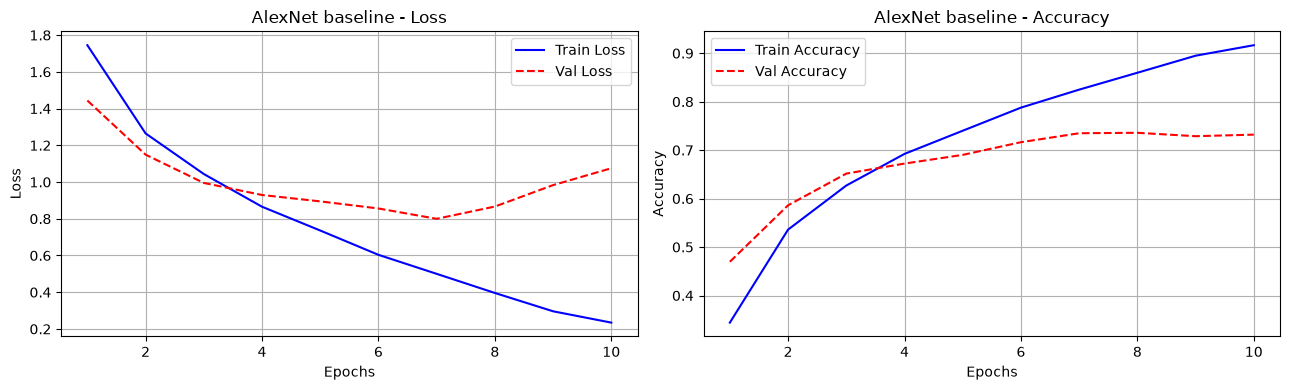

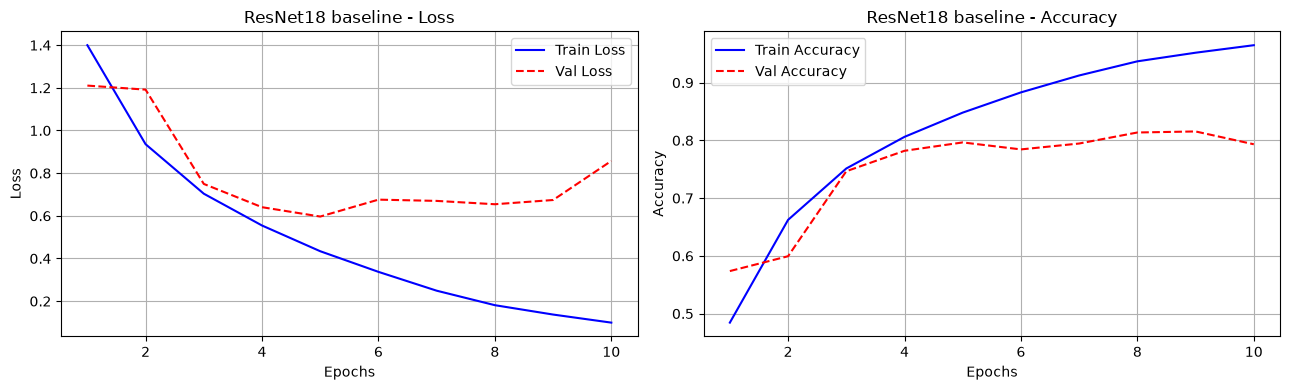

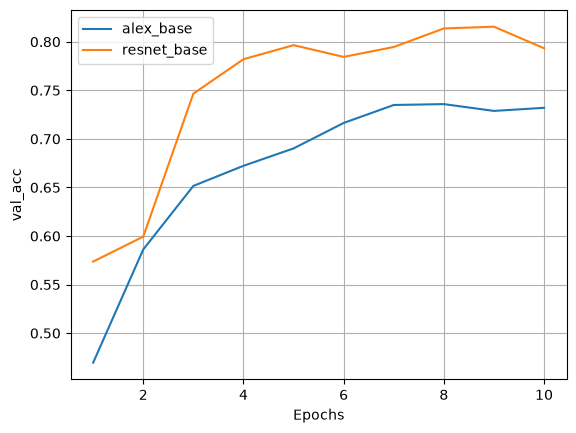

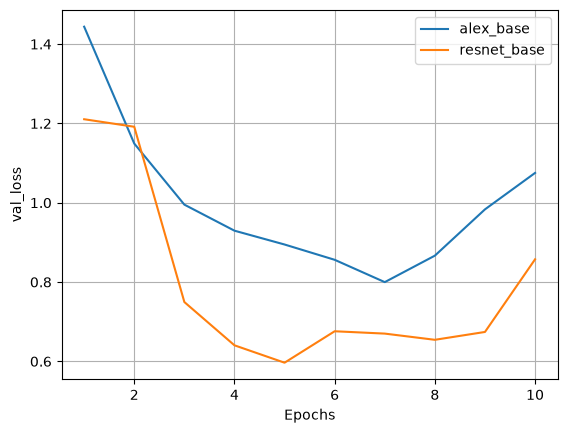

In [75]:
plot_metrics(results['alex_base'], "AlexNet baseline")
plot_metrics(results['resnet_base'], "ResNet18 baseline")

plot_compare(pick('alex_base', 'resnet_base'), 'val_acc')
plot_compare(pick('alex_base', 'resnet_base'), 'val_loss')

# Task 3 Investigate Capacity and Regularization

alex_w0.5 | Epoch 1/10 | Train loss: 1.7782 | Train acc: 0.3308 | Val loss: 1.4523 | Val accuracy: 0.4596
alex_w0.5 | Epoch 2/10 | Train loss: 1.3581 | Train acc: 0.4980 | Val loss: 1.2793 | Val accuracy: 0.5399
alex_w0.5 | Epoch 3/10 | Train loss: 1.1472 | Train acc: 0.5822 | Val loss: 1.0990 | Val accuracy: 0.6082
alex_w0.5 | Epoch 4/10 | Train loss: 0.9731 | Train acc: 0.6516 | Val loss: 0.9381 | Val accuracy: 0.6675
alex_w0.5 | Epoch 5/10 | Train loss: 0.8449 | Train acc: 0.6998 | Val loss: 0.8869 | Val accuracy: 0.6874
alex_w0.5 | Epoch 6/10 | Train loss: 0.7438 | Train acc: 0.7370 | Val loss: 0.8478 | Val accuracy: 0.7030
alex_w0.5 | Epoch 7/10 | Train loss: 0.6489 | Train acc: 0.7689 | Val loss: 0.7870 | Val accuracy: 0.7280
alex_w0.5 | Epoch 8/10 | Train loss: 0.5680 | Train acc: 0.7979 | Val loss: 0.7860 | Val accuracy: 0.7393
alex_w0.5 | Epoch 9/10 | Train loss: 0.4982 | Train acc: 0.8237 | Val loss: 0.7944 | Val accuracy: 0.7388
alex_w0.5 | Epoch 10/10 | Train loss: 0.4138 |

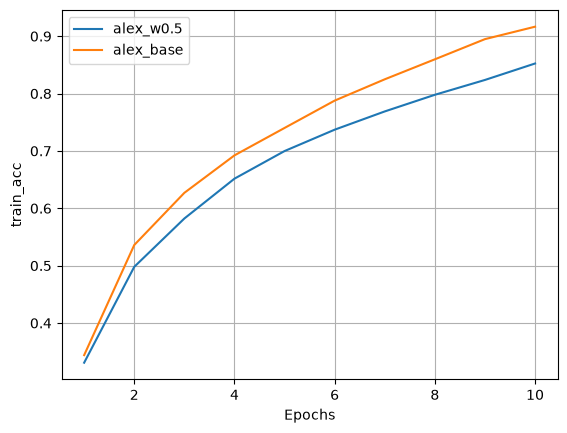

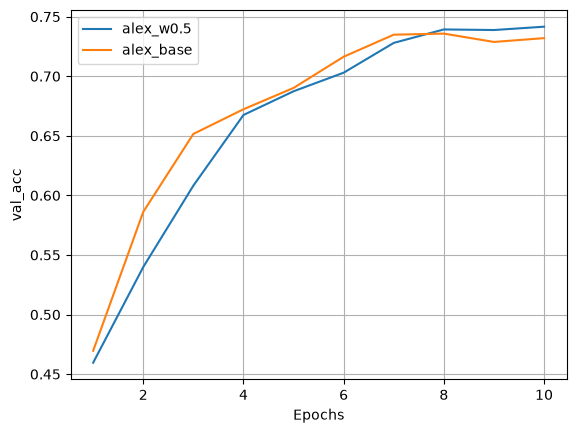

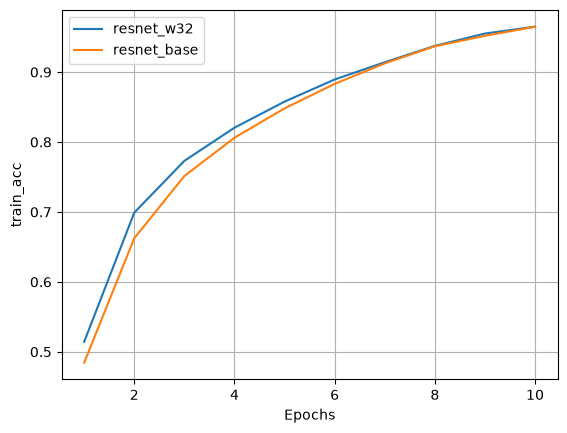

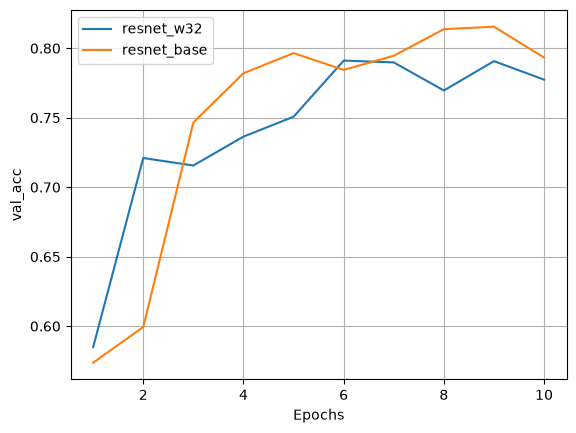

In [76]:
# Width
#normal width for both is (64,128,256,...)

#Alex with half the width (instead of 64,128... , it is 32, 64,...)
torch.manual_seed(seed)
results['alex_w0.5'] = run(AlexNet(width=0.5), "alex_w0.5")


#Same deal with Resnet
torch.manual_seed(seed)
results['resnet_w32'] = run(ResNet18(width=32), "resnet_w32")



plot_compare(pick('alex_w0.5', 'alex_base'), 'train_acc')
plot_compare(pick('alex_w0.5', 'alex_base'), 'val_acc')

plot_compare(pick('resnet_w32', 'resnet_base'), 'train_acc')
plot_compare(pick('resnet_w32', 'resnet_base'), 'val_acc')


#Both narrow implementations reach a bit lower acc for both train, but they reach it with less time and much less parameters.
#narrower alex reaches a bit better val acc and has less overfitting which is an improvement

#Overfitting still appears but a but less as the trains and val acc are closer

alex_extra1 | Epoch 1/10 | Train loss: 1.9285 | Train acc: 0.2600 | Val loss: 1.5851 | Val accuracy: 0.4097
alex_extra1 | Epoch 2/10 | Train loss: 1.3942 | Train acc: 0.4808 | Val loss: 1.3020 | Val accuracy: 0.5274
alex_extra1 | Epoch 3/10 | Train loss: 1.1647 | Train acc: 0.5759 | Val loss: 1.1977 | Val accuracy: 0.5833
alex_extra1 | Epoch 4/10 | Train loss: 1.0177 | Train acc: 0.6342 | Val loss: 0.9931 | Val accuracy: 0.6498
alex_extra1 | Epoch 5/10 | Train loss: 0.8966 | Train acc: 0.6819 | Val loss: 0.9433 | Val accuracy: 0.6713
alex_extra1 | Epoch 6/10 | Train loss: 0.7983 | Train acc: 0.7170 | Val loss: 0.8902 | Val accuracy: 0.6947
alex_extra1 | Epoch 7/10 | Train loss: 0.7198 | Train acc: 0.7455 | Val loss: 0.8388 | Val accuracy: 0.7106
alex_extra1 | Epoch 8/10 | Train loss: 0.6505 | Train acc: 0.7706 | Val loss: 0.8806 | Val accuracy: 0.7030
alex_extra1 | Epoch 9/10 | Train loss: 0.5727 | Train acc: 0.7987 | Val loss: 0.8254 | Val accuracy: 0.7268
alex_extra1 | Epoch 10/10 | 

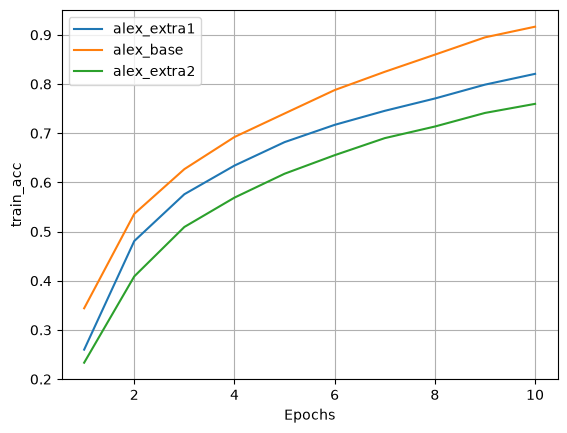

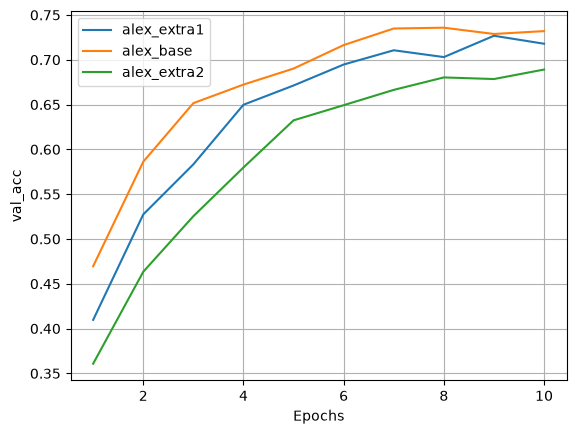

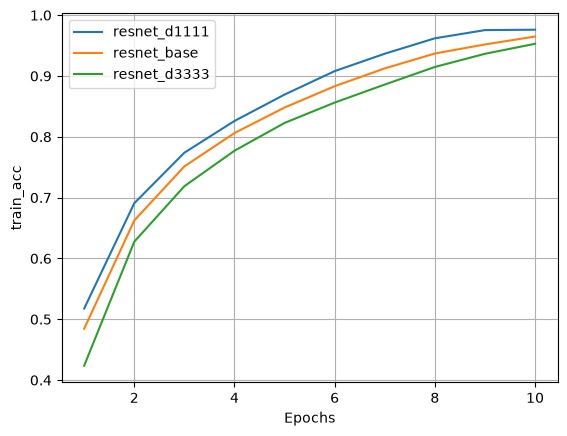

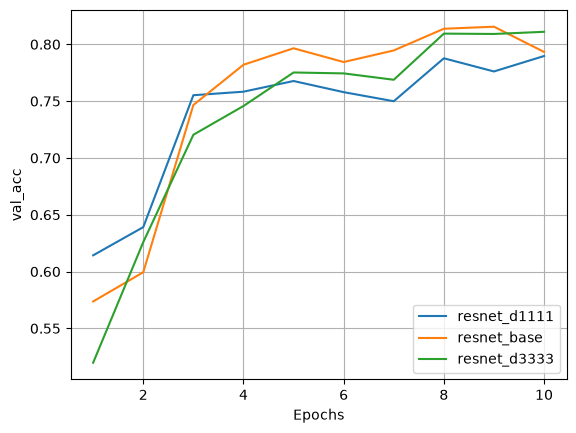

In [77]:
# Depth


#Original depth is 5 conv layers. Each extra conv layer makes the model deeper
torch.manual_seed(seed)
results['alex_extra1']  = run(AlexNet(extra_convs=1), "alex_extra1")
torch.manual_seed(seed)
results['alex_extra2']  = run(AlexNet(extra_convs=2), "alex_extra2")

# Original Depth is [2,2,2,2]. setting it to 1,1,1,1 makes it more shallow, and 3,3,3,3 makes it deeper
torch.manual_seed(seed)
results['resnet_d1111'] = run(ResNet18(blocks=(1,1,1,1)), "resnet_d1111")
torch.manual_seed(seed)
results['resnet_d3333'] = run(ResNet18(blocks=(3,3,3,3)), "resnet_d3333")


plot_compare(pick('alex_extra1', 'alex_base', 'alex_extra2'), 'train_acc')
plot_compare(pick('alex_extra1', 'alex_base', 'alex_extra2'), 'val_acc')

plot_compare(pick('resnet_d1111', 'resnet_base', 'resnet_d3333'), 'train_acc')
plot_compare(pick('resnet_d1111', 'resnet_base', 'resnet_d3333'), 'val_acc')


#For alexnet, it reaches lower training accuracy but it takes longer with more paramters. 
#But the overfitting is less since the train acc is closer to val acc
#They reach almost the same val acc, which makes it not worth the trouble
#When adding 2 extra conv layer, we get the "vanishing gradient" problem where the acc cannot get over 9%
#Making the model much deeper without any other optimization techniques causes this

#for resnet the deeper it goes the less training acc it has, which in theory also is bad since it takes more effort and gets less results.
#it is worthy to note that the overfitting is the smallest with the 2 extra conv model, but it still has lower val acc

alex_drop20 | Epoch 1/10 | Train loss: 1.8069 | Train acc: 0.3135 | Val loss: 1.4393 | Val accuracy: 0.4666
alex_drop20 | Epoch 2/10 | Train loss: 1.3412 | Train acc: 0.5040 | Val loss: 1.1856 | Val accuracy: 0.5633
alex_drop20 | Epoch 3/10 | Train loss: 1.1196 | Train acc: 0.5988 | Val loss: 1.0728 | Val accuracy: 0.6200
alex_drop20 | Epoch 4/10 | Train loss: 0.9464 | Train acc: 0.6636 | Val loss: 0.9767 | Val accuracy: 0.6568
alex_drop20 | Epoch 5/10 | Train loss: 0.8218 | Train acc: 0.7118 | Val loss: 0.8767 | Val accuracy: 0.6984
alex_drop20 | Epoch 6/10 | Train loss: 0.7077 | Train acc: 0.7512 | Val loss: 0.7964 | Val accuracy: 0.7339
alex_drop20 | Epoch 7/10 | Train loss: 0.6127 | Train acc: 0.7833 | Val loss: 0.7945 | Val accuracy: 0.7365
alex_drop20 | Epoch 8/10 | Train loss: 0.5253 | Train acc: 0.8145 | Val loss: 0.8183 | Val accuracy: 0.7284
alex_drop20 | Epoch 9/10 | Train loss: 0.4411 | Train acc: 0.8452 | Val loss: 0.8102 | Val accuracy: 0.7418
alex_drop20 | Epoch 10/10 | 

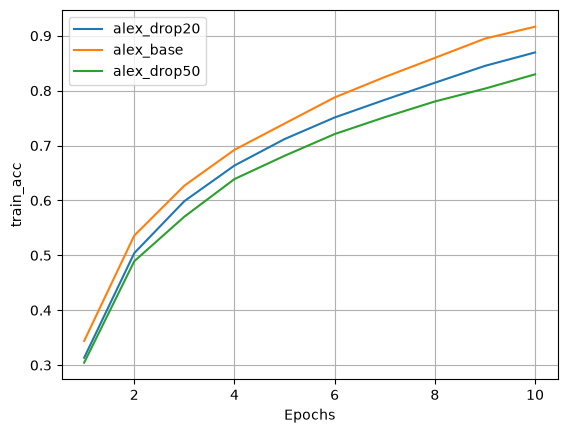

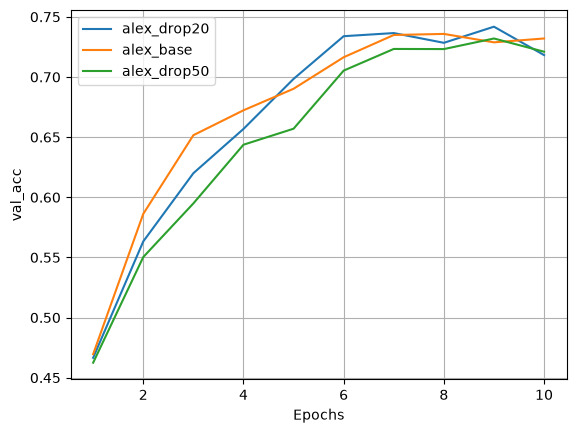

In [78]:
# Dropout 
#ResNet have built in batchNorm so it wouldn't make much sense to do dropout optimization too.
#number is percentage of nodes dropped. 0 is baseline, 0.2 is 20% (moderate), and 50% is high
torch.manual_seed(seed)
results['alex_drop20'] = run(AlexNet(dropout=0.2), "alex_drop20")
torch.manual_seed(seed)
results['alex_drop50']   = run(AlexNet(dropout=0.5), "alex_drop50")

plot_compare(pick('alex_drop20', 'alex_base', 'alex_drop50'), 'train_acc')
plot_compare(pick('alex_drop20','alex_base', 'alex_drop50'), 'val_acc')



#The best opt for now. Although they reach less training acc, they reach similar val acc, and the 50 version even has a tiny bit more val acc
#They both have less overfitting
#it takes a few sec more which isn't an issue.

alex_l2 | Epoch 1/10 | Train loss: 1.8090 | Train acc: 0.3095 | Val loss: 1.4950 | Val accuracy: 0.4408
alex_l2 | Epoch 2/10 | Train loss: 1.3866 | Train acc: 0.4843 | Val loss: 1.2574 | Val accuracy: 0.5369
alex_l2 | Epoch 3/10 | Train loss: 1.1804 | Train acc: 0.5689 | Val loss: 1.1951 | Val accuracy: 0.5678
alex_l2 | Epoch 4/10 | Train loss: 1.0156 | Train acc: 0.6338 | Val loss: 1.0371 | Val accuracy: 0.6269
alex_l2 | Epoch 5/10 | Train loss: 0.8938 | Train acc: 0.6811 | Val loss: 0.9073 | Val accuracy: 0.6743
alex_l2 | Epoch 6/10 | Train loss: 0.7843 | Train acc: 0.7221 | Val loss: 0.8443 | Val accuracy: 0.7047
alex_l2 | Epoch 7/10 | Train loss: 0.7043 | Train acc: 0.7502 | Val loss: 0.8745 | Val accuracy: 0.7022
alex_l2 | Epoch 8/10 | Train loss: 0.6293 | Train acc: 0.7782 | Val loss: 0.8258 | Val accuracy: 0.7152
alex_l2 | Epoch 9/10 | Train loss: 0.5553 | Train acc: 0.8040 | Val loss: 0.8184 | Val accuracy: 0.7248
alex_l2 | Epoch 10/10 | Train loss: 0.4871 | Train acc: 0.8299 |

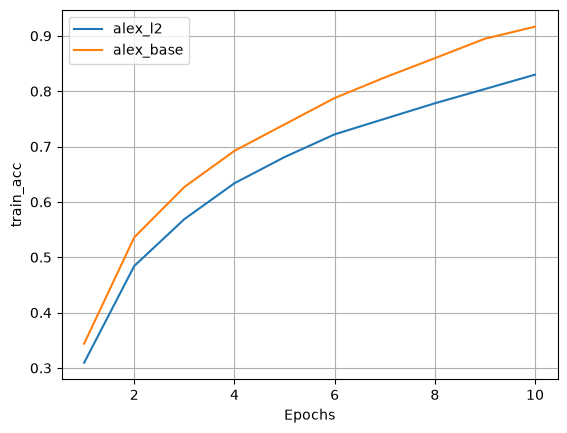

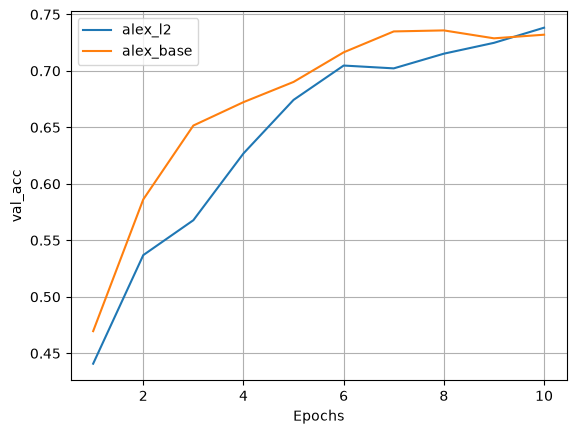

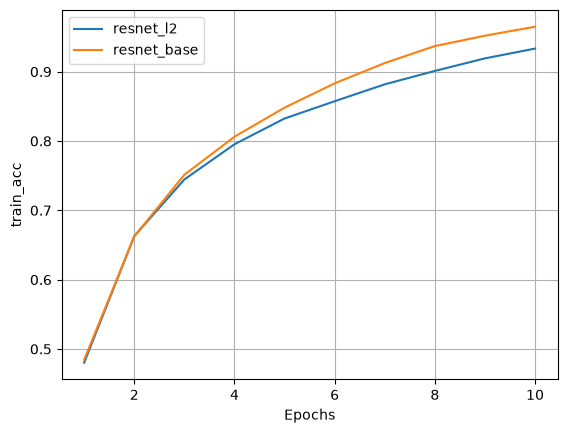

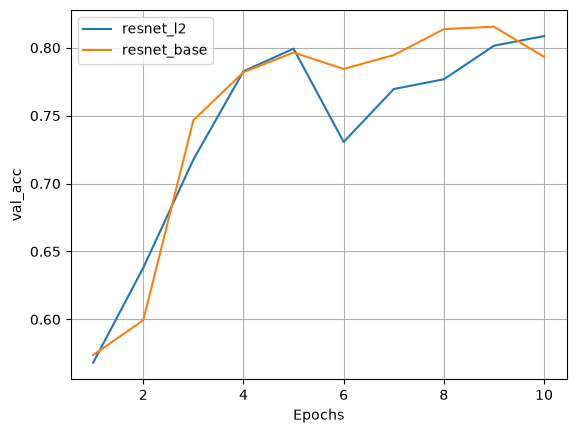

In [79]:
# L2 Regularization(Implemented with weight decay)
#A moderate value of 1e-4 was chosen. This might help with overfitting
#combination of batchNorm in Resnet and this might be interesting to comment on
torch.manual_seed(seed)
results['alex_l2']   = run(AlexNet(), "alex_l2", weight_decay=1e-4)
torch.manual_seed(seed)
results['resnet_l2'] = run(ResNet18(), "resnet_l2", weight_decay=1e-4)



plot_compare(pick('alex_l2', 'alex_base'), 'train_acc')
plot_compare(pick('alex_l2', 'alex_base'), 'val_acc')

plot_compare(pick('resnet_l2', 'resnet_base'), 'train_acc')
plot_compare(pick('resnet_l2', 'resnet_base'), 'val_acc')


#For alex it reaches less train acc but higher val acc, which means less overfitting with the same nb of paramters and same time
#for resnet it has less train and val acc, but still less overfitting

# Task 4. Evaluate Robustness 

In [80]:
#First create the augmented training dataset

# Augmentations performed on the augmented dataset:
# mirror left-right
# rotate by a random angle in [-15, 15] degrees
# Change coloring
augment_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),               
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
])

# New CIFAR-10 copy
train_dataset_aug = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=True, transform=augment_transform
)

# getting the augmented training set
train_subset_aug = Subset(train_dataset_aug, train_subset.indices)

# new loader
train_loader_aug = DataLoader(train_subset_aug, batch_size=128, shuffle=True)
# val_loader and test_loader stay unchanged: no augmentation on evaluation data

In [81]:
#Now create the corrupted evaluation dataset - #DO ONLY ONCE
#uses seed so it is reproducable

def make_corrupted_sets(dataset, seed=587):
    g = torch.Generator().manual_seed(seed)
    imgs = torch.stack([dataset[i][0] for i in range(len(dataset))])
    labels = torch.tensor(dataset.targets)

    # 1) Gaussian noise: add random noise to every pixel, then clip back to [0,1]
    noise = torch.randn(imgs.shape, generator=g) * 0.1
    noisy = (imgs + noise).clamp(0, 1)

    # 2) Rotation: each image gets its own random angle in [-30, 30] degrees
    angles = (torch.rand(len(imgs), generator=g) * 60 - 30).tolist()
    rotated = torch.stack([TF.rotate(img, a) for img, a in zip(imgs, angles)])

    # 3) Blur: smooths out fine detail
    blurred = TF.gaussian_blur(imgs, kernel_size=5, sigma=1.5)

    return {
        "clean": TensorDataset(imgs, labels),
        "noise": TensorDataset(noisy, labels),
        "rotate": TensorDataset(rotated, labels),
        "blur": TensorDataset(blurred, labels),
    }

corrupted_sets = make_corrupted_sets(test_dataset)
corrupted_loaders = {name: DataLoader(ds, batch_size=128, shuffle=False)
                     for name, ds in corrupted_sets.items()}

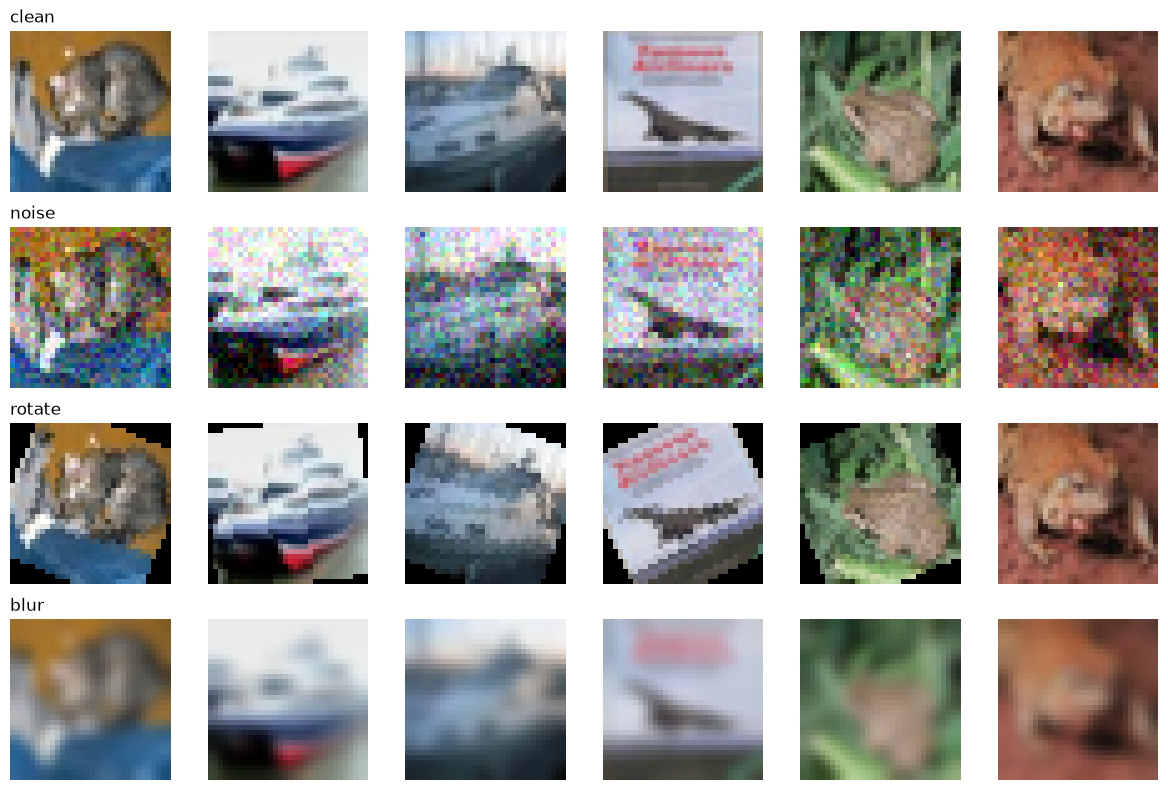

In [82]:
# Visualize
fig, axes = plt.subplots(4, 6, figsize=(12, 8))
for row, (name, ds) in enumerate(corrupted_sets.items()):
    for col in range(6):
        img, label = ds[col]
        axes[row, col].imshow(img.permute(1, 2, 0))   # (C,H,W) -> (H,W,C) for matplotlib
        axes[row, col].axis("off")
        if col == 0:
            axes[row, col].set_title(name, loc="left")
plt.tight_layout(); plt.show()

alex_aug | Epoch 1/10 | Train loss: 1.8263 | Train acc: 0.3124 | Val loss: 1.5029 | Val accuracy: 0.4361
alex_aug | Epoch 2/10 | Train loss: 1.4044 | Train acc: 0.4795 | Val loss: 1.2460 | Val accuracy: 0.5490
alex_aug | Epoch 3/10 | Train loss: 1.2090 | Train acc: 0.5606 | Val loss: 1.1284 | Val accuracy: 0.6024
alex_aug | Epoch 4/10 | Train loss: 1.0636 | Train acc: 0.6161 | Val loss: 0.9801 | Val accuracy: 0.6530
alex_aug | Epoch 5/10 | Train loss: 0.9627 | Train acc: 0.6560 | Val loss: 0.9044 | Val accuracy: 0.6846
alex_aug | Epoch 6/10 | Train loss: 0.8825 | Train acc: 0.6877 | Val loss: 0.8293 | Val accuracy: 0.7066
alex_aug | Epoch 7/10 | Train loss: 0.8140 | Train acc: 0.7118 | Val loss: 0.7990 | Val accuracy: 0.7217
alex_aug | Epoch 8/10 | Train loss: 0.7605 | Train acc: 0.7319 | Val loss: 0.8049 | Val accuracy: 0.7241
alex_aug | Epoch 9/10 | Train loss: 0.7133 | Train acc: 0.7466 | Val loss: 0.7711 | Val accuracy: 0.7342
alex_aug | Epoch 10/10 | Train loss: 0.6696 | Train acc

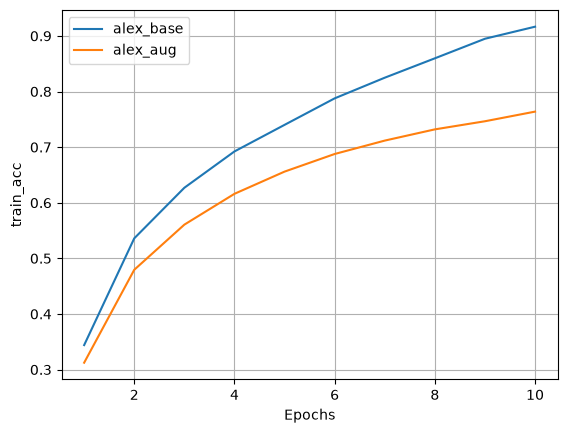

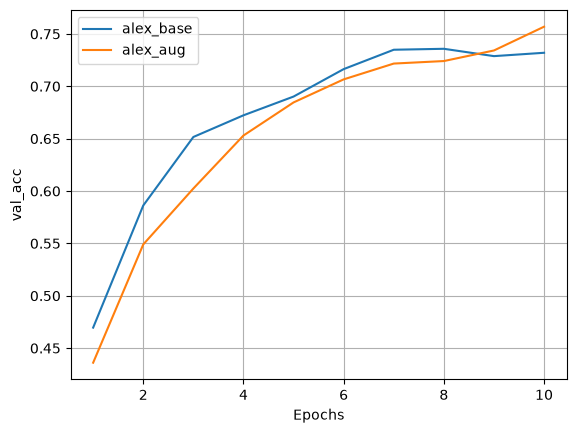

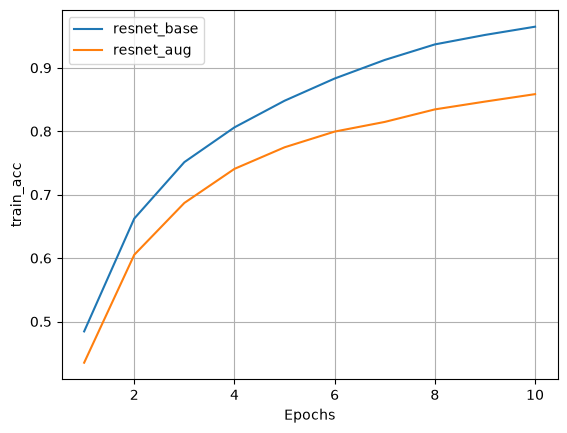

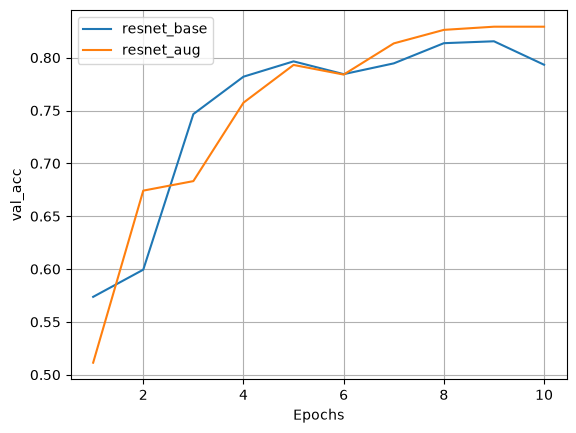

In [83]:
#Train the augmented models and compare
torch.manual_seed(seed)
results['alex_aug'] = run(AlexNet(), "alex_aug", loader=train_loader_aug)
torch.manual_seed(seed)
results['resnet_aug'] = run(ResNet18(), "resnet_aug", loader=train_loader_aug)

plot_compare(pick('alex_base', 'alex_aug'), 'train_acc')
plot_compare(pick('alex_base', 'alex_aug'), 'val_acc')
plot_compare(pick('resnet_base', 'resnet_aug'), 'train_acc')
plot_compare(pick('resnet_base', 'resnet_aug'), 'val_acc')

In [84]:
# Evaluate
#We measure how good the base vs augmented on each of the evaluation sets
# we have clean, noise, rotation, and blur

def load_best(model, name):
    model = model.to(device)
    model.load_state_dict(torch.load(f"{name}_best.pth", map_location=device))
    return model

models = {
    "alex_base":  load_best(AlexNet(),   "alexnet"),
    "alex_aug":   load_best(AlexNet(),   "alex_aug"),
    "resnet_base": load_best(ResNet18(), "resnet"),
    "resnet_aug":  load_best(ResNet18(), "resnet_aug"),
}

robust = {}   # robust["resnet_aug"]["rotate"] = accuracy on the rotated test set
for model_name, model in models.items():
    robust[model_name] = {}
    for corruption_name, loader in corrupted_loaders.items():
        _, acc = evaluate(model, loader)
        robust[model_name][corruption_name] = acc

# Print one line per model
for model_name, accs in robust.items():
    print(model_name,
          f"| clean: {accs['clean']:.3f}",
          f"| noise: {accs['noise']:.3f}",
          f"| rotate: {accs['rotate']:.3f}",
          f"| blur: {accs['blur']:.3f}")

# Training cost, taken from the stored results
for key in ["alex_base", "alex_aug", "resnet_base", "resnet_aug"]:
    print(key, f"| train time: {results[key]['time']:.0f}s")

alex_base | clean: 0.731 | noise: 0.471 | rotate: 0.540 | blur: 0.412
alex_aug | clean: 0.750 | noise: 0.442 | rotate: 0.677 | blur: 0.484
resnet_base | clean: 0.814 | noise: 0.497 | rotate: 0.617 | blur: 0.241
resnet_aug | clean: 0.827 | noise: 0.372 | rotate: 0.716 | blur: 0.230
alex_base | train time: 83s
alex_aug | train time: 156s
resnet_base | train time: 198s
resnet_aug | train time: 268s


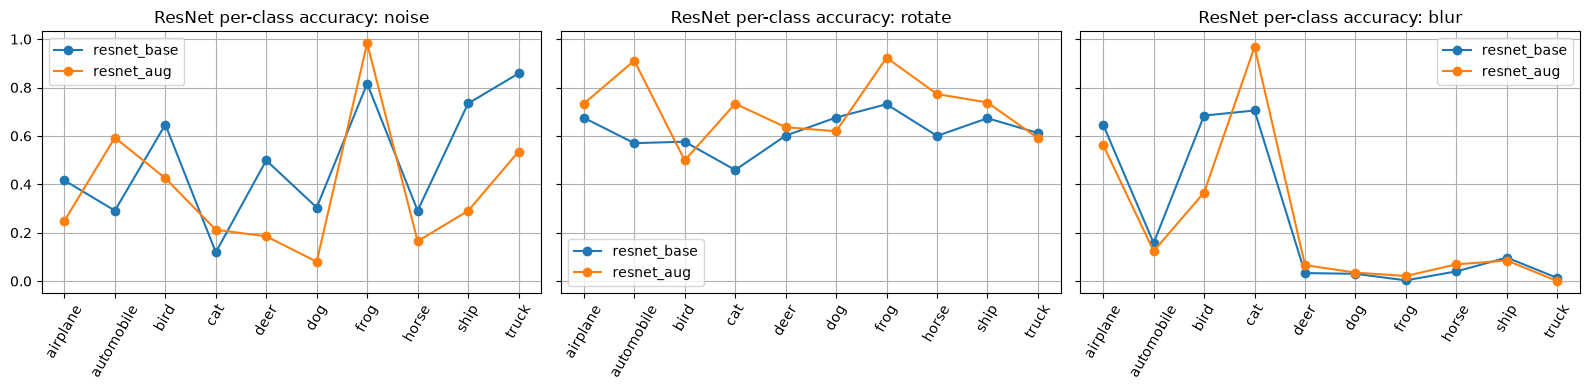

In [85]:
#"the types of errors introduced by different transformations,"
#Dont really understand the question, but assume what classes are most hurt by each transformation
def per_class_acc(model, loader):
    model.eval()
    correct = torch.zeros(10); total = torch.zeros(10)
    with torch.no_grad():
        for x, y in loader:
            pred = model(x.to(device)).argmax(1).cpu()
            for c in range(10):
                mask = (y == c)
                correct[c] += (pred[mask] == c).sum()
                total[c] += mask.sum()
    return (correct / total).numpy()

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, cname in zip(axes, ["noise", "rotate", "blur"]):
    for mname in ["resnet_base", "resnet_aug"]:
        ax.plot(classes, per_class_acc(models[mname], corrupted_loaders[cname]), marker="o", label=mname)
    ax.set_title(f"ResNet per-class accuracy: {cname}")
    ax.tick_params(axis="x", rotation=60); ax.legend(); ax.grid(True)
plt.tight_layout(); plt.show()